# Final Assignment: Part 1 - Create Visualizations using Matplotlib, Seaborn & Folium
## Analyzing the Impact of Economic Recessions on Automobile Sales
### Company: XYZ Automotives
---

### Initial Setup and Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# Load historical automobile sales dataset
df = pd.read_csv('historical_automobile_sales.csv')
print('Data downloaded and read into a dataframe!')
df.head()

Data downloaded and read into a dataframe!


,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City
0,1/31/1980,1980,Jan,1,108.24,0.50,27483.571,1558,7,60.223,0.010000,5.4,456.0,Supperminicar,Georgia
1,2/29/1980,1980,Feb,1,98.75,0.75,24308.678,3048,4,45.986,-0.309594,4.8,555.9,Supperminicar,New York
2,3/31/1980,1980,Mar,1,107.48,0.20,28238.443,3137,3,35.141,-0.308614,3.4,620.0,Mediumfamilycar,New York
3,4/30/1980,1980,Apr,1,115.01,1.00,32615.149,1653,7,45.673,0.230596,4.2,702.8,Supperminicar,Illinois
4,5/31/1980,1980,May,1,98.72,0.20,23829.233,1319,4,52.997,0.138197,5.3,770.4,Smallfamiliycar,California


In [2]:
df.describe()

,Year,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales
count,528.000000,528.000000,528.000000,528.000000,528.000000,528.000000,528.000000,528.000000,528.000000,528.000000,528.000000
mean,2001.500000,0.214015,101.140170,0.575795,24964.991956,3067.456439,6.064394,40.073903,-0.242001,2.453977,2352.718068
std,12.710467,0.410526,10.601154,0.454477,4888.073433,1139.564637,1.968350,16.249714,0.861268,1.119019,1645.321284
min,1980.000000,0.000000,73.900000,0.000000,8793.663000,1009.000000,3.000000,12.508000,-4.227601,1.000000,102.000000
25%,1990.750000,0.000000,94.035000,0.250000,21453.300500,2083.500000,4.000000,27.237500,-0.574049,1.600000,793.950000
50%,2001.500000,0.000000,100.740000,0.500000,25038.691500,3072.000000,6.000000,39.214500,-0.013162,2.300000,2182.600000
75%,2012.250000,0.000000,108.240000,0.750000,28131.684750,4067.250000,8.000000,53.506500,0.388932,2.900000,3614.800000
max,2023.000000,1.000000,131.670000,1.500000,44263.657000,4983.000000,9.000000,70.374000,0.815074,6.000000,21147.000000


### TASK 1.1: Line chart to show how Average Annual Automobile Sales fluctuate from year to year

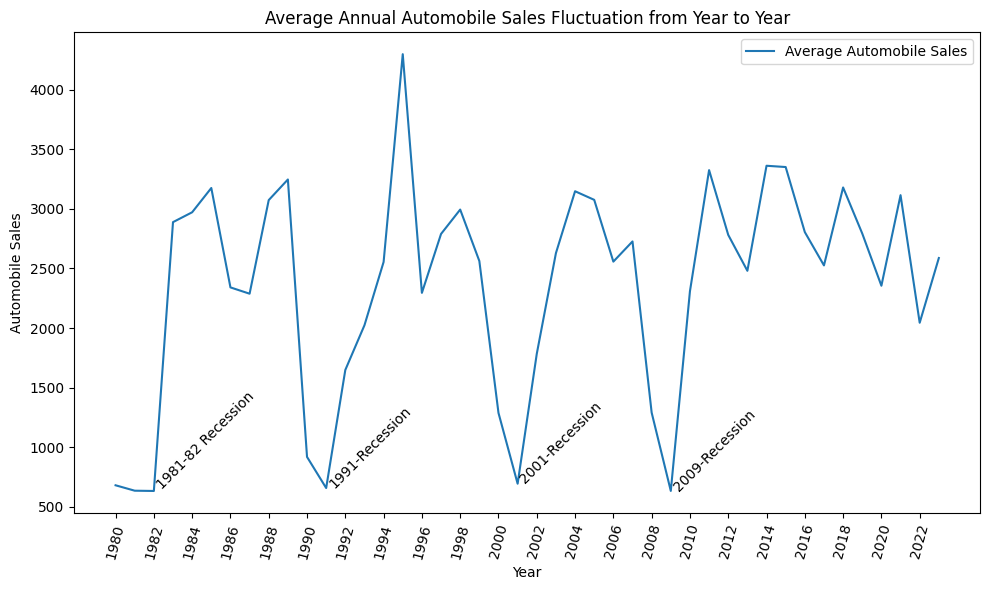

In [3]:
# TASK 1.1: Line chart to show how Average Annual Automobile Sales fluctuate from year to year
df_line = df.groupby('Year')['Automobile_Sales'].mean()

plt.figure(figsize=(10, 6))
df_line.plot(kind='line')
plt.xticks(list(range(1980, 2024, 2)), rotation=75)
plt.xlabel('Year')
plt.ylabel('Automobile Sales')
plt.title('Average Annual Automobile Sales Fluctuation from Year to Year')
plt.text(1982, 650, '1981-82 Recession', rotation=45)
plt.text(1991, 655, '1991-Recession', rotation=45)
plt.text(2001, 693, '2001-Recession', rotation=45)
plt.text(2009, 633, '2009-Recession', rotation=45)
plt.legend(['Average Automobile Sales'])
plt.tight_layout()
plt.show()

**Inference:** Automobile sales experienced drastic declines during all major recession periods (1981-82, 1991, 2001, 2008-09).

### TASK 1.2: Line chart to analyze how do trends in advertising expenditure correlate with automobile sales during non-recession periods

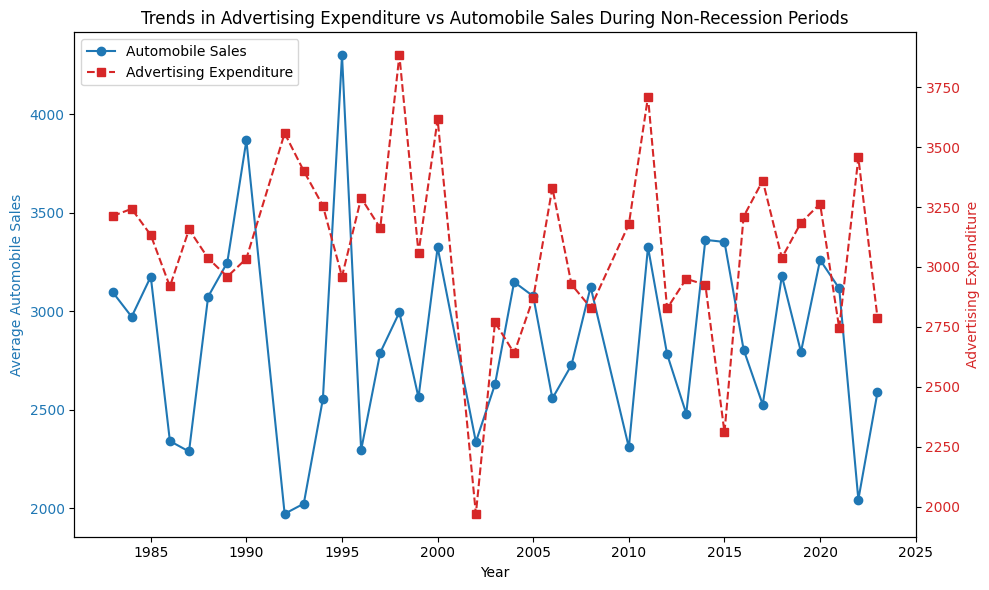

In [4]:
# TASK 1.2: Line chart to analyze how do trends in advertising expenditure correlate with automobile sales during non-recession periods
non_rec_data = df[df['Recession'] == 0]
df_ad_sales = non_rec_data.groupby('Year')[['Advertising_Expenditure', 'Automobile_Sales']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(df_ad_sales['Year'], df_ad_sales['Automobile_Sales'], color='tab:blue', marker='o', label='Automobile Sales')
ax1.set_xlabel('Year')
ax1.set_ylabel('Average Automobile Sales', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(df_ad_sales['Year'], df_ad_sales['Advertising_Expenditure'], color='tab:red', marker='s', linestyle='--', label='Advertising Expenditure')
ax2.set_ylabel('Advertising Expenditure', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Trends in Advertising Expenditure vs Automobile Sales During Non-Recession Periods')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.show()

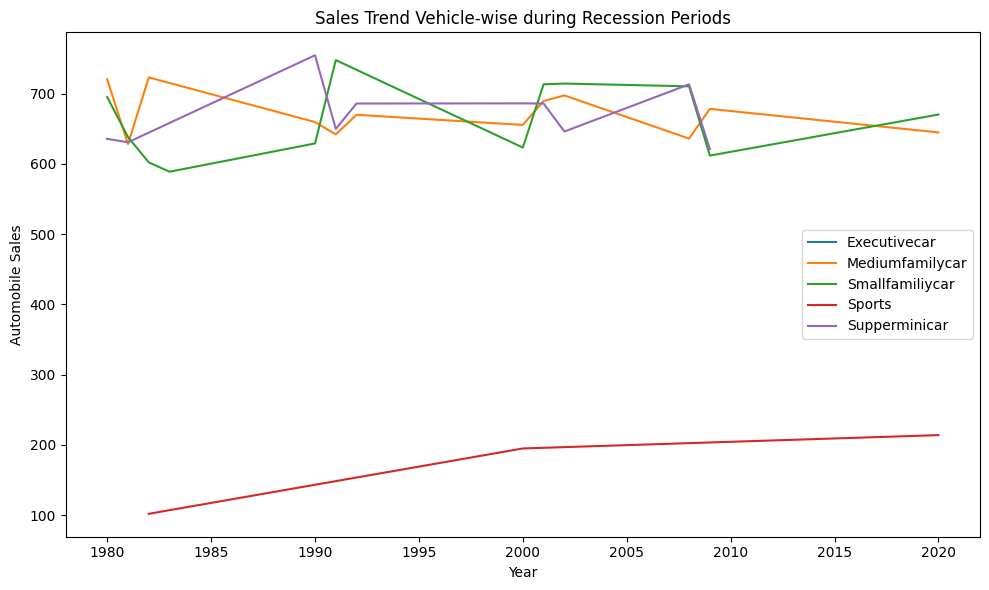

In [5]:
# TASK 1.2 (Additional): Sales trend vehicle-wise during recession periods
df_rec = df[df['Recession'] == 1]
df_Mline = df_rec.groupby(['Year', 'Vehicle_Type'], as_index=False)['Automobile_Sales'].mean()
df_Mline.set_index('Year', inplace=True)
df_Mline = df_Mline.groupby(['Vehicle_Type'])['Automobile_Sales']

plt.figure(figsize=(10, 6))
df_Mline.plot(kind='line')
plt.xlabel('Year')
plt.ylabel('Automobile Sales')
plt.title('Sales Trend Vehicle-wise during Recession Periods')
plt.legend()
plt.tight_layout()
plt.show()

**Inference:** During non-recession periods, higher advertising expenditure correlates positively with increased sales volume. During recessions, Sports vehicles suffer the steepest decline while Superminicar and Smallfamilycar remain relatively resilient.

### TASK 1.3: Bar chart to compare the Vehicle-Wise Sales During Recession and Non-Recession Periods

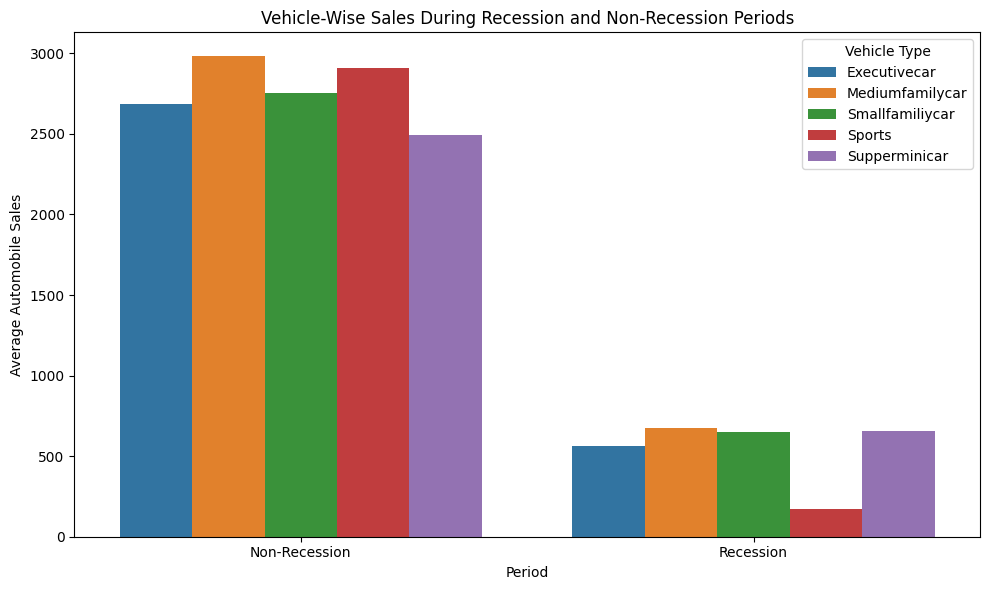

In [6]:
# TASK 1.3: Bar chart to compare the Vehicle-Wise Sales During Recession and Non-Recession Periods
dd = df.groupby(['Recession', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Recession', y='Automobile_Sales', hue='Vehicle_Type', data=dd)
plt.xticks(ticks=[0, 1], labels=['Non-Recession', 'Recession'])
plt.xlabel('Period')
plt.ylabel('Average Automobile Sales')
plt.title('Vehicle-Wise Sales During Recession and Non-Recession Periods')
plt.legend(title='Vehicle Type')
plt.tight_layout()
plt.show()

**Inference:** Sales are higher in non-recession periods for all vehicle types. Executive cars and sports cars experience the lowest sales during recessions, whereas SuperMiniCar performs better than ExecutiveCar in recession.

### TASK 1.4: Subplots to compare the variations in GDP during recession and non-recession periods by developing line plots for each period

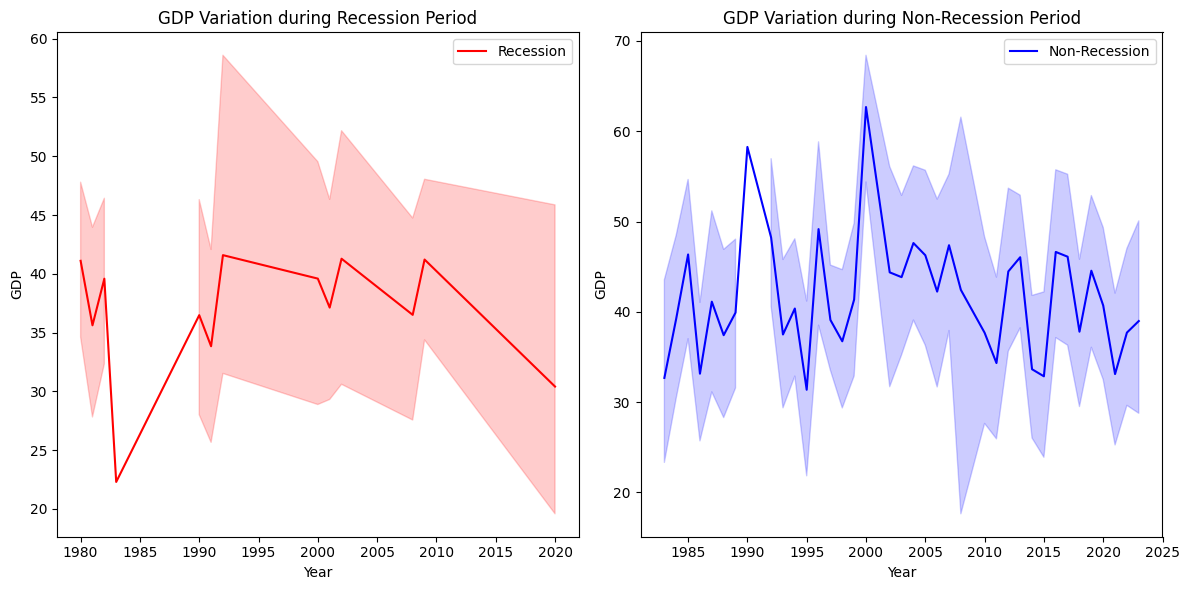

In [7]:
# TASK 1.4: Subplots to compare the variations in GDP during recession and non-recession periods
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]

fig = plt.figure(figsize=(12, 6))
ax0 = fig.add_subplot(1, 2, 1)
ax1 = fig.add_subplot(1, 2, 2)

sns.lineplot(x='Year', y='GDP', data=rec_data, label='Recession', ax=ax0, color='red')
ax0.set_xlabel('Year')
ax0.set_ylabel('GDP')
ax0.set_title('GDP Variation during Recession Period')

sns.lineplot(x='Year', y='GDP', data=non_rec_data, label='Non-Recession', ax=ax1, color='blue')
ax1.set_xlabel('Year')
ax1.set_ylabel('GDP')
ax1.set_title('GDP Variation during Non-Recession Period')

plt.tight_layout()
plt.show()

**Inference:** GDP drops visibly during recession periods, reducing purchasing power, whereas GDP steadily climbs during non-recession years.

### TASK 1.5: Bubble plot for displaying the impact of seasonality on Automobile Sales

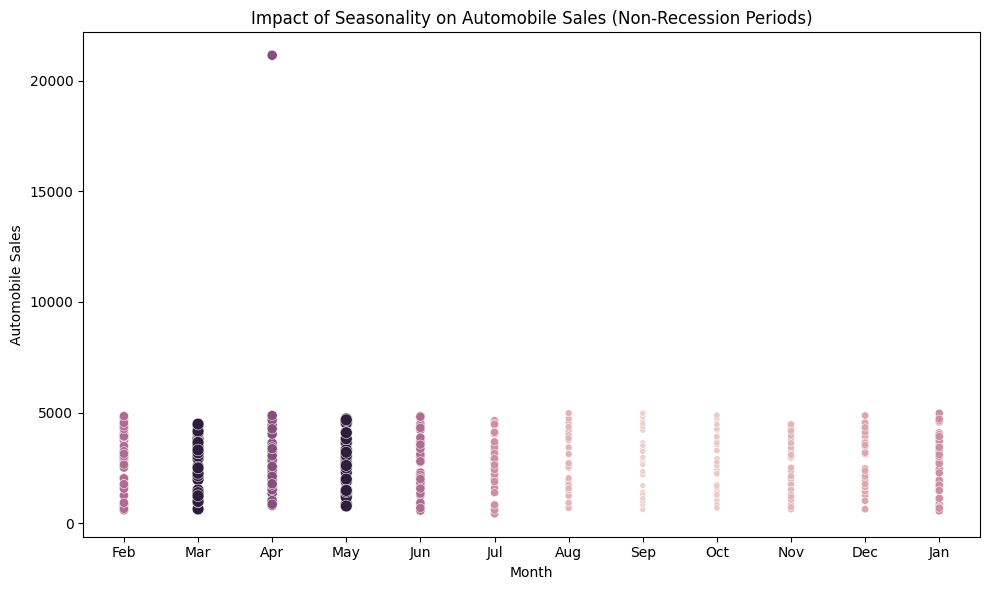

In [8]:
# TASK 1.5: Bubble plot for displaying the impact of seasonality on Automobile Sales
non_rec_data = df[df['Recession'] == 0]
size = non_rec_data['Seasonality_Weight']

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=non_rec_data,
    x='Month',
    y='Automobile_Sales',
    size=size,
    hue='Seasonality_Weight',
    legend=False
)
plt.xlabel('Month')
plt.ylabel('Automobile Sales')
plt.title('Impact of Seasonality on Automobile Sales (Non-Recession Periods)')
plt.tight_layout()
plt.show()

**Inference:** Seasonality weight clearly dictates monthly vehicle sales spikes, with spring and summer months showing higher sales volumes.

### TASK 1.6: Scatter plot to identify the correlation between average vehicle price relate to the sales volume during recessions

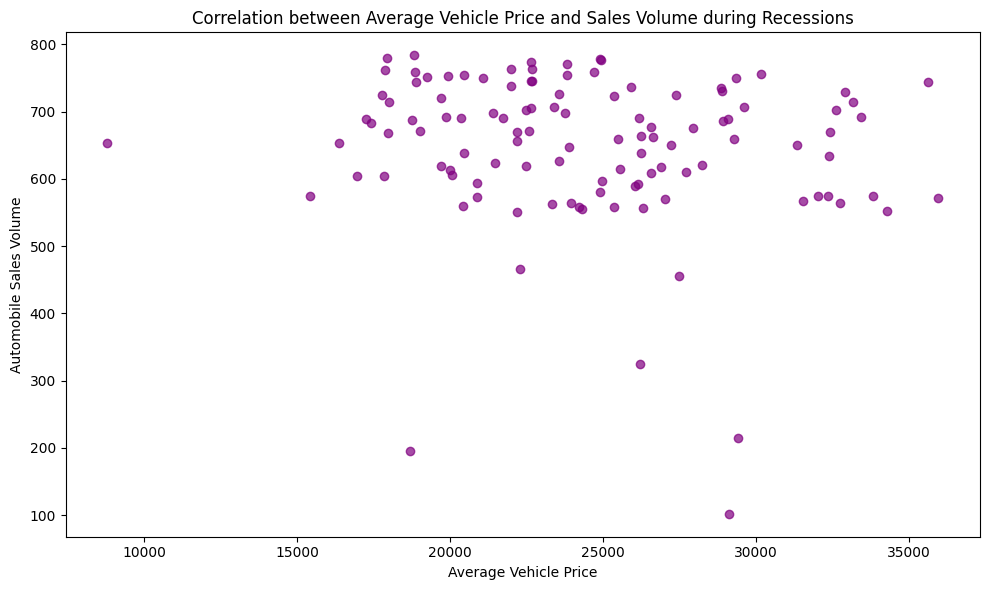

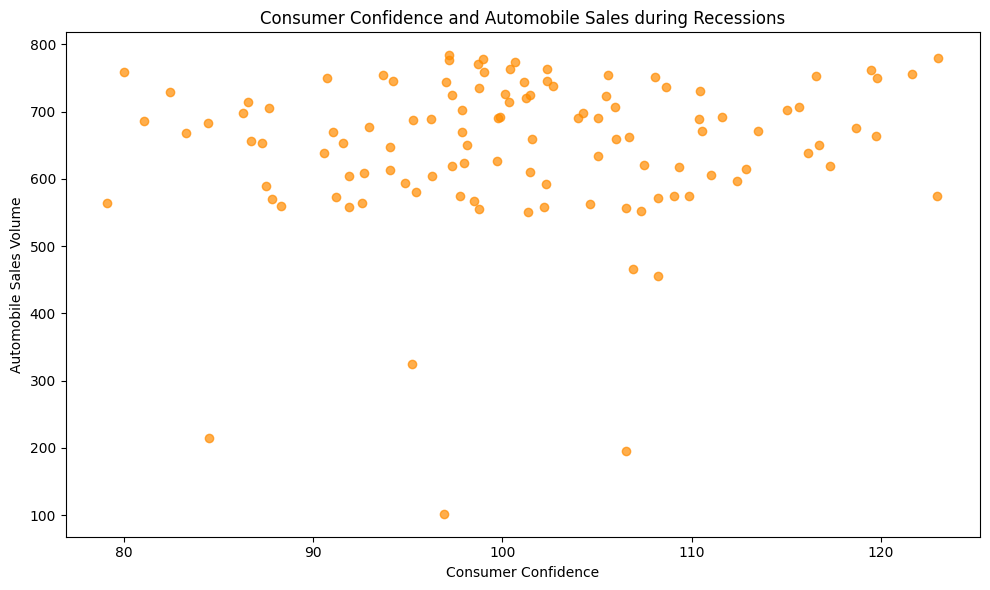

In [9]:
# TASK 1.6: Scatter plot to identify the correlation between average vehicle price relate to the sales volume during recessions
rec_data = df[df['Recession'] == 1]

plt.figure(figsize=(10, 6))
plt.scatter(rec_data['Price'], rec_data['Automobile_Sales'], alpha=0.7, color='purple')
plt.xlabel('Average Vehicle Price')
plt.ylabel('Automobile Sales Volume')
plt.title('Correlation between Average Vehicle Price and Sales Volume during Recessions')
plt.tight_layout()
plt.show()

# Consumer Confidence vs Automobile Sales during Recessions
plt.figure(figsize=(10, 6))
plt.scatter(rec_data['Consumer_Confidence'], rec_data['Automobile_Sales'], color='darkorange', alpha=0.7)
plt.xlabel('Consumer Confidence')
plt.ylabel('Automobile Sales Volume')
plt.title('Consumer Confidence and Automobile Sales during Recessions')
plt.tight_layout()
plt.show()

**Inference:** There is an inverse correlation between vehicle price and sales volume during recessions: higher-priced vehicles experience significantly reduced sales volume.

### TASK 1.7: Pie chart to display the portion of advertising expenditure of XYZAutomotives during recession and non-recession periods

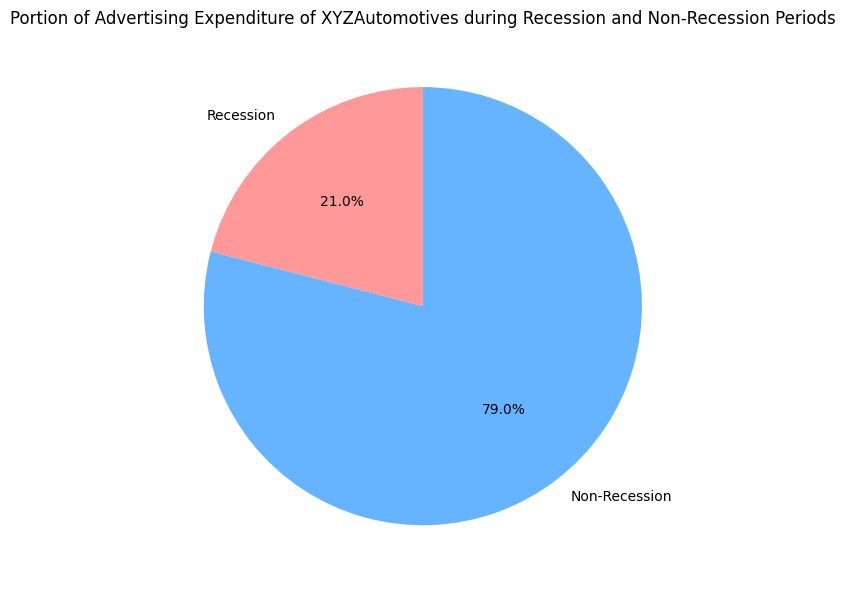

In [10]:
# TASK 1.7: Pie chart to display the portion of advertising expenditure of XYZAutomotives during recession and non-recession periods
Rdata = df[df['Recession'] == 1]
NRdata = df[df['Recession'] == 0]

RAtotal = Rdata['Advertising_Expenditure'].sum()
NRAtotal = NRdata['Advertising_Expenditure'].sum()

plt.figure(figsize=(8, 6))
labels = ['Recession', 'Non-Recession']
sizes = [RAtotal, NRAtotal]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#ff9999', '#66b3ff'])
plt.title('Portion of Advertising Expenditure of XYZAutomotives during Recession and Non-Recession Periods')
plt.tight_layout()
plt.show()

**Inference:** XYZAutomotives spent approximately 79% of its advertising budget during non-recession periods and 21% during recession periods.

### TASK 1.8: Pie chart to display the total Advertisement expenditure for each vehicle type during the recession period

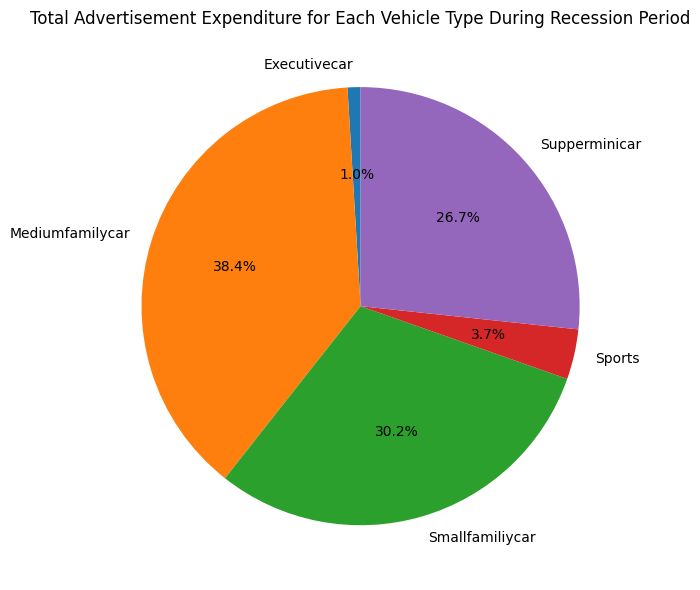

In [11]:
# TASK 1.8: Pie chart to display the total Advertisement expenditure for each vehicle type during the recession period
Rdata = df[df['Recession'] == 1]
VTexpenditure = Rdata.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()

plt.figure(figsize=(10, 6))
labels = VTexpenditure.index
sizes = VTexpenditure.values
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title('Total Advertisement Expenditure for Each Vehicle Type During Recession Period')
plt.tight_layout()
plt.show()

**Inference:** Mediumfamilycar and Smallfamilycar represented the largest share of advertising spend during recessions.

### TASK 1.9: Line chart to analyze the effect of the unemployment rate on vehicle type and sales during the Recession Period

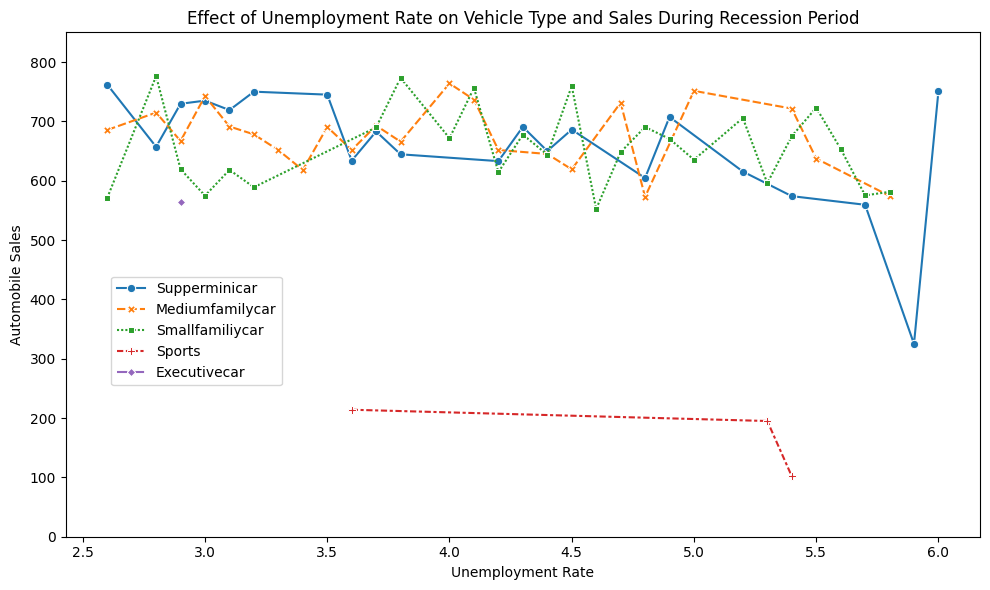

In [12]:
# TASK 1.9: Line chart to analyze the effect of the unemployment rate on vehicle type and sales during the Recession Period
df_rec = df[df['Recession'] == 1]

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=df_rec,
    x='unemployment_rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    style='Vehicle_Type',
    markers=True,
    err_style=None
)
plt.ylim(0, 850)
plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales During Recession Period')
plt.legend(loc=(0.05, 0.3))
plt.tight_layout()
plt.show()

**Inference:** As unemployment rises during recessions, sales across all categories decrease, with luxury/sports vehicles experiencing the most severe drop.

### OPTIONAL: TASK 1.10 Create a map on the highest sales region/offices of the company during recession period

In [13]:
# TASK 1.10: Choropleth map of company sales by region/city during recession
import json
with open('us-states.json') as f:
    us_states_json = json.load(f)

recession_data = df[df['Recession'] == 1]
sales_by_city = recession_data.groupby('City')['Automobile_Sales'].sum().reset_index()

map1 = folium.Map(location=[37.0902, -95.7129], zoom_start=4)
choropleth = folium.Choropleth(
    geo_data=us_states_json,
    data=sales_by_city,
    columns=['City', 'Automobile_Sales'],
    key_on='feature.properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name='Automobile Sales during Recession'
).add_to(map1)
choropleth.geojson.add_child(folium.features.GeoJsonTooltip(['name'], labels=True))
map1